In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

from multiprocessing import Pool
import sys
from astropy.io import fits

In [2]:
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

# SBI
two step SBI:
- train NN from signals to (S8, Om)
- from S8(train), Om(train) and S8(real), Om(real) to posterior distribution

alternative plan
- train NN from each signal (C_ell, Peaks and Minima, etc.) to predict S8 Om individually - use S8(train, C_ell), Om(train, C_ell), S8(train, peaks), Om(train, peaks)... and S8(real), Om(real) to posterior distribution



## data C_ell
50 cosmologies * 50 realizations

2500 datas, each cosmology lets split ~20% as validation, which is 50 * 40 training + 50 * 10 testing

in the SBI paper, they first use optuna to optimize the hyperparameters, and then use 

In [3]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)
Om = cosmo_pars[:,1]
S8 = cosmo_pars[:,3]

In [4]:
cut_Cl_tomo4 = False         # I remember that tomo bin 4 has outliers
stats = 'Gabriela'
# stats = 'DI'

if stats == 'Gabriela':
    if cut_Cl_tomo4:
        dir = '/home/hedi/HSCNG/SBI/leaveout/'
    else:
        dir = '/home/hedi/HSCNG/SBI/leaveout_nocut/'
elif stats == 'DI':
    if cut_Cl_tomo4:
        dir = '/home/hedi/HSCNG/SBI/leaveout_DI/'
    else:
        dir = '/home/hedi/HSCNG/SBI/leaveout_DI_nocut/'

In [5]:
Cl_tomo = []

for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied = []
    for cosmology_id in range(50):
        Cls = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy')     # 50 realizations here
            Cls.append(dat)
        Cls = np.array(Cls)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied.append(np.average(Cls, axis=0, weights=weights))

    Cl_tomo.append(np.array(Cl_cosmo_varied))
Cl_tomo = np.array(Cl_tomo)

In [6]:
def pre_process_C_ell(Cl_tomo, ell_min=100, ell_max=2000):
    """
    Preprocess the C_ell data by selecting a range of ell values and flattening the data.
    
    Parameters:
    Cl_tomo (numpy.ndarray): The input C_ell data with shape (tomobin, cosmology_id, realization, ell).
    ell_min (int): The minimum ell value to consider.
    ell_max (int): The maximum ell value to consider.
    
    Returns:
    numpy.ndarray: The preprocessed and flattened C_ell data.
    """
    import pymaster as nmt
    if stats == 'Gabriela':
        l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
    elif stats == 'DI':
        l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500), 20))
    binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
    xx = binner.get_effective_ells()

    slice_ell = (xx >= ell_min) & (xx <= ell_max)          # apply a cut here.
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    if cut_Cl_tomo4:
        Cl_concat = np.concatenate(Cl_tomo[:3, :, :, slice_ell], axis=2)  # Discard tomo bin 4
    else:
        Cl_concat = np.concatenate(Cl_tomo[:, :, :, slice_ell], axis=2)
    return Cl_concat

In [7]:
C_ell_concat = pre_process_C_ell(Cl_tomo, ell_min=300, ell_max=2000)

## data peaks & minima

In [8]:
peak_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/peaks/model{cosmology_id}_Peaks_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/peaks/mock_results/model{cosmology_id}_peaks_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    peak_tomo.append(np.array(signal_cosmo_varied))
peak_tomo = np.array(peak_tomo)

min_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/minima/model{cosmology_id}_Minima_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/peaks/mock_results/model{cosmology_id}_minimums_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)     # field, realization, kappa
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    min_tomo.append(np.array(signal_cosmo_varied))
min_tomo = np.array(min_tomo)

In [9]:
def pre_process_peaks(peak_tomo, threshold=15):
    """
    Preprocess the peak data by applying a threshold and flattening the data across tomobin, cosmology_id, and realization dimensions.
    
    Parameters:
    - peak_tomo: numpy array of shape (tomobin, cosmology_id, realization, peak_value)
    - threshold: float, the threshold value to filter peaks
    
    Returns:
    - peak_concat: numpy array of shape (tomobin * cosmology_id * realization, filtered_peak_values)
    """
    # Apply threshold
    select_indice = (peak_tomo > threshold).any(axis=(0, 1, 2))     # it is safe, as far as I examined
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    peak_concat = np.concatenate(peak_tomo[:, :, :, select_indice], axis=2)
    
    return peak_concat

In [10]:
peak_concat = pre_process_peaks(peak_tomo, threshold=0)
min_concat = pre_process_peaks(min_tomo, threshold=0)

# peak_concat = pre_process_peaks(peak_tomo, threshold=15)
# min_concat = pre_process_peaks(min_tomo, threshold=15)

## data PDF

In [11]:
pdf_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/pdf/model{cosmology_id}_pdf_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/pdf/mock_results/model{cosmology_id}_pdf_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    pdf_tomo.append(np.array(signal_cosmo_varied))
pdf_tomo = np.array(pdf_tomo)

In [12]:
# pdf_concat = np.concatenate(pdf_tomo[:, :, :, 3:], axis=2)      # cut the first 3 bins according to Thiele et al. 23
pdf_concat = np.concatenate(pdf_tomo[:, :, :, :], axis=2)

# data MFs

In [13]:
V0_tomo = []
V1_tomo = []
V2_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V0_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/MFs/mock_results/model{cosmology_id}_V0_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V0_tomo.append(np.array(signal_cosmo_varied))
V0_tomo = np.array(V0_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V1_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/MFs/mock_results/model{cosmology_id}_V1_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V1_tomo.append(np.array(signal_cosmo_varied))
V1_tomo = np.array(V1_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            if stats == 'Gabriela':
                dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V2_z{tomo}_{field}.npy')     # 50 realizations here
            elif stats == 'DI':
                dat = np.load(f'/home/hedi/HSCNG/MFs/mock_results/model{cosmology_id}_V2_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V2_tomo.append(np.array(signal_cosmo_varied))
V2_tomo = np.array(V2_tomo)

In [14]:
V0_concat = np.concatenate(V0_tomo, axis=2)
V1_concat = np.concatenate(V1_tomo, axis=2)
V2_concat = np.concatenate(V2_tomo, axis=2)

# concat data together

In [15]:
def train_test_split(
    data,
    label,
    test_size=0.2,
    leaveoutindex=None,
    random_state=42,
):  # for each cosmology, split realizations into train and test sets.

    rng = np.random.default_rng(random_state)

    n_cosmo, n_real, _ = data.shape
    n_train = int(n_real * (1 - test_size))

    label = np.asarray(label)

    X_train = []
    X_test = []

    theta_train = []
    theta_test = []

    for cosmo_id in range(n_cosmo):

        if leaveoutindex is not None and cosmo_id == leaveoutindex:
            continue

        # ONE realization split for this cosmology
        indices = rng.permutation(n_real)

        idx_train = indices[:n_train]
        idx_test = indices[n_train:]

        X_train.append(data[cosmo_id, idx_train, :])
        X_test.append(data[cosmo_id, idx_test, :])

        theta_c = np.atleast_1d(label[cosmo_id])

        theta_train.append(
            np.repeat(
                theta_c[None, :],
                len(idx_train),
                axis=0,
            )
        )

        theta_test.append(
            np.repeat(
                theta_c[None, :],
                len(idx_test),
                axis=0,
            )
        )
    

    dat_train = np.concatenate(X_train)
    dat_test = np.concatenate(X_test)
    label_train = np.concatenate(theta_train)
    label_test = np.concatenate(theta_test)


    x_mean = dat_train.mean(axis=0)
    x_std = dat_train.std(axis=0)

    # protect against zero-variance bins
    x_std[x_std == 0] = 1.0

    x_train_np = (dat_train - x_mean) / x_std
    x_test_np = (dat_test - x_mean) / x_std

    x_train = torch.tensor(x_train_np, dtype=torch.float32)
    x_test = torch.tensor(x_test_np, dtype=torch.float32)

    # SBI theta must have shape (N, n_parameters)
    theta_train = torch.tensor(
        label_train,
        dtype=torch.float32
    )

    theta_test = torch.tensor(
        label_test,
        dtype=torch.float32
    )

    theta_mean = theta_train.mean(dim=0)
    theta_std = theta_train.std(dim=0)
    theta_train_normalized = (theta_train - theta_mean) / theta_std
    theta_test_normalized = (theta_test - theta_mean) / theta_std

    return (
        x_train,
        x_test,
        theta_train_normalized,
        theta_test_normalized,
        x_mean,
        x_std,
        theta_mean,
        theta_std
    )

In [16]:
def train_test_split_cosmo(
    data,
    label,
    valid_size=0.2,
    leaveoutindex=None,
    random_state=42,
):

    rng = np.random.default_rng(random_state)

    # renormalize the data and labels
    x_mean = np.mean(data, axis=0)
    x_std = np.std(data, axis=0)
    x_std[x_std == 0] = 1.0

    data_normalized = (data - x_mean) / x_std

    label = np.asarray(label)
    lab_mean = np.mean(label, axis=0)
    lab_std = np.std(label, axis=0)
    label_normalized = (label - lab_mean) / lab_std


    n_cosmo, n_real, _ = data.shape
    n_valid = int(n_real * valid_size)

    cosmo_train = []
    cosmo_valid = []
    cosmo_ids = [
        i for i in range(n_cosmo) if i != leaveoutindex
    ]
    
    rng.shuffle(cosmo_ids)
    cosmo_test = [leaveoutindex] if leaveoutindex is not None else []
    cosmo_valid = cosmo_ids[:n_valid]
    cosmo_train = cosmo_ids[n_valid:]

    # train-validation-test split for cosmologies
    X_train = []
    X_test = []
    X_valid = []

    theta_train = []
    theta_test = []
    theta_valid = []

    for cosmo_id in range(n_cosmo):
        i = cosmo_id
        if i in cosmo_train:
            X_train.append(data_normalized[cosmo_id, :])
            theta_c = np.atleast_1d(label_normalized[cosmo_id])
            theta_train.append(
                np.repeat(
                    theta_c[None, :],
                    data_normalized.shape[1],
                    axis=0,
                )
            )
        elif i in cosmo_valid:
            X_valid.append(data_normalized[cosmo_id, :])
            theta_c = np.atleast_1d(label_normalized[cosmo_id])
            theta_valid.append(
                np.repeat(
                    theta_c[None, :],
                    data_normalized.shape[1],
                    axis=0,
                )
            )
        elif i in cosmo_test:
            X_test.append(data_normalized[cosmo_id, :])
            theta_c = np.atleast_1d(label_normalized[cosmo_id])
            theta_test.append(
                np.repeat(
                    theta_c[None, :],
                    data_normalized.shape[1],
                    axis=0,
                )
            )

    dat_train = np.concatenate(X_train)
    dat_valid = np.concatenate(X_valid)
    dat_test = np.concatenate(X_test)         # len X_test == 1

    label_train = np.concatenate(theta_train)
    label_valid = np.concatenate(theta_valid)
    label_test = np.concatenate(theta_test)

    # convert to torch tensors
    x_train = torch.tensor(dat_train, dtype=torch.float32)
    x_valid = torch.tensor(dat_valid, dtype=torch.float32)
    x_test = torch.tensor(dat_test, dtype=torch.float32)

    theta_train = torch.tensor(
        label_train,
        dtype=torch.float32
    )
    theta_valid = torch.tensor(
        label_valid,
        dtype=torch.float32
    )
    theta_test = torch.tensor(
        label_test,
        dtype=torch.float32
    )

    return dict(
        x_train=x_train,
        x_valid=x_valid,
        x_test=x_test,
        theta_train=theta_train,
        theta_valid=theta_valid,
        theta_test=theta_test,
        x_mean=x_mean,
        x_std=x_std,
        theta_mean=lab_mean,
        theta_std=lab_std
    )

In [17]:
train_data = {}
leaveoutindex = 41

train_data['C_ell'] = train_test_split_cosmo(C_ell_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['peaks'] = train_test_split_cosmo(peak_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['minima'] = train_test_split_cosmo(min_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['pdf'] = train_test_split_cosmo(pdf_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
train_data['MFs'] = train_test_split_cosmo(np.concatenate([V0_concat, V1_concat, V2_concat], axis=2), label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
# same random state will give same train-test splitting.

# train_data['C_ell'] = train_test_split(C_ell_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)       # random state should be the same.
# train_data['peaks'] = train_test_split(peak_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)
# train_data['minima'] = train_test_split(min_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)
# train_data['pdf'] = train_test_split(pdf_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)
# train_data['MFs'] = train_test_split(np.concatenate([V0_concat, V1_concat, V2_concat], axis=2), label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)

In [18]:
theta_train_normalized = train_data['C_ell']['theta_train']
theta_test_normalized = train_data['C_ell']['theta_valid']
theta_mean = train_data['C_ell']['theta_mean']
theta_std = train_data['C_ell']['theta_std']

theta_train = (theta_train_normalized + theta_mean) * theta_std
for k in train_data.keys():
    theta_train_normalized = train_data['C_ell']['theta_train']
    theta_test_normalized = train_data['C_ell']['theta_valid']
    theta_mean = train_data['C_ell']['theta_mean']
    theta_std = train_data['C_ell']['theta_std']

    theta_train_1 = (theta_train_normalized + theta_mean) * theta_std

    print(torch.isclose(theta_train_1, theta_train).all())

/tmp/ipykernel_232575/207373655.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train = (theta_train_normalized + theta_mean) * theta_std
/tmp/ipykernel_232575/207373655.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train_1 = (theta_train_normalized + theta_mean) * theta_std


tensor(True)
tensor(True)
tensor(True)
tensor(True)
tensor(True)


# Step 1: train compression

In [19]:
for k, v in train_data.items():
    print('{}: {} => {}'.format(k, v['x_train'].shape[1], v['theta_train'].shape[1]))

C_ell: 24 => 2
peaks: 76 => 2
minima: 76 => 2
pdf: 76 => 2
MFs: 228 => 2


In [20]:
class ParameterNN(nn.Module):
    def __init__(self, n_input, n_latent=2):
        super().__init__()
        self.n_latent = n_latent
        if n_input <= 20:
            dims = [n_input, 32, 16, n_latent]

        elif n_input <= 100:
            dims = [n_input, 64, 32, n_latent]

        else:
            dims = [n_input, 128, 64, 32, n_latent]

        layers = []

        for i in range(len(dims) - 2):
            layers += [
                nn.Linear(dims[i], dims[i+1]),
                nn.GELU(),
            ]

        layers += [
            nn.Linear(dims[-2], dims[-1])
        ]

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [21]:
from torch.utils.data import DataLoader, TensorDataset
import copy

train x_train => theta_train, test with x_valid, theta_valid

In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [23]:
def train_model(x_train, theta_train_normalized, x_valid, theta_valid_normalized, device):

    model = ParameterNN(
        n_input=x_train.shape[1],
        n_latent=2,
    ).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    x_train = x_train.to(device)
    theta_train_normalized = theta_train_normalized.to(device)
    x_valid = x_valid.to(device)
    theta_valid_normalized = theta_valid_normalized.to(device)

    train_loader = DataLoader(
        TensorDataset(x_train, theta_train_normalized),
        batch_size=128,
        shuffle=True,
    )


    loss_train = []
    loss_test = []

    best_loss = np.inf
    best_state = None
    patience = 30
    bad_epochs = 0

    for epoch in range(500):

        # -----------------
        # training
        # -----------------
        model.train()

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            pred = model(xb)
            loss = ((pred - yb)**2).mean()

            loss.backward()
            optimizer.step()

        # -----------------
        # validation
        # -----------------
        model.eval()

        with torch.no_grad():
            val_pred = model(x_valid)
            val_loss = ((val_pred - theta_valid_normalized)**2).mean().item()
            loss_test.append(val_loss)

            pred = model(x_train)
            loss = ((pred - theta_train_normalized)**2).mean().item()
            loss_train.append(loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    model.load_state_dict(best_state)

    return model, loss_train, loss_test, bad_epochs

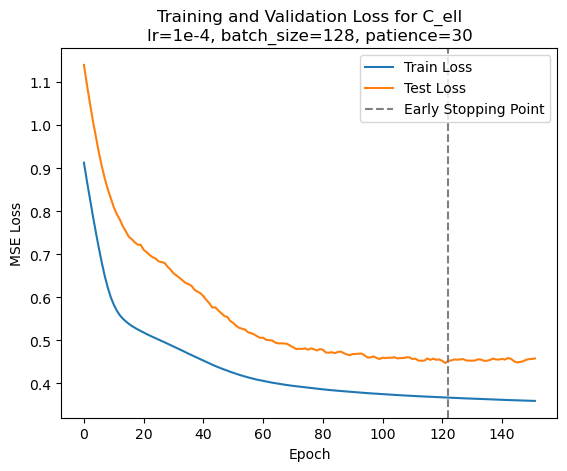

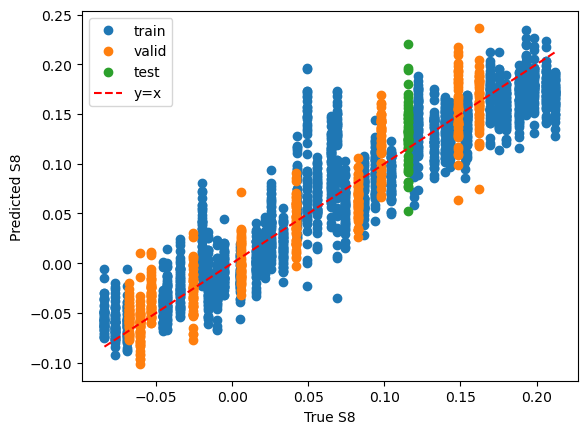

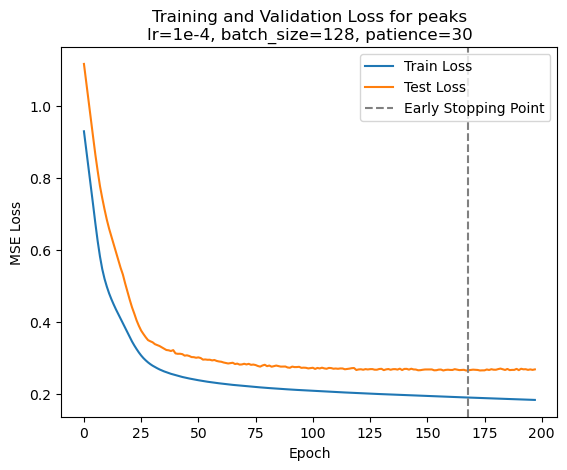

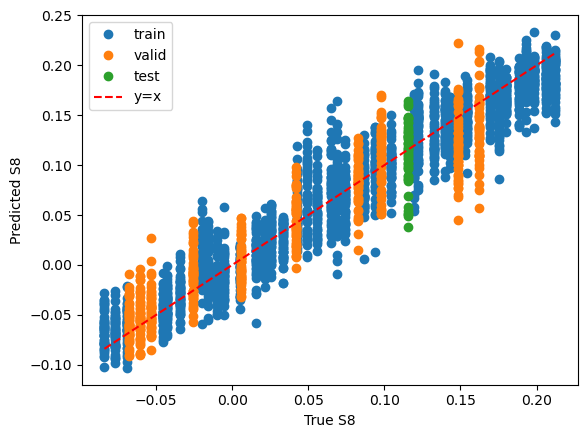

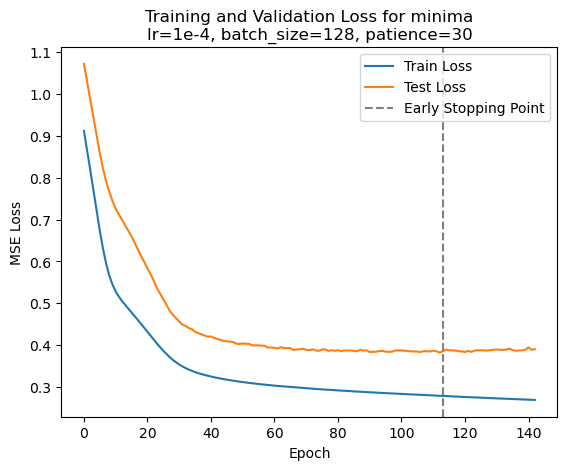

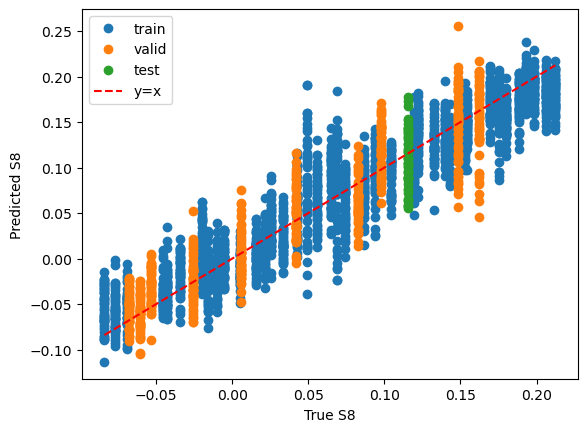

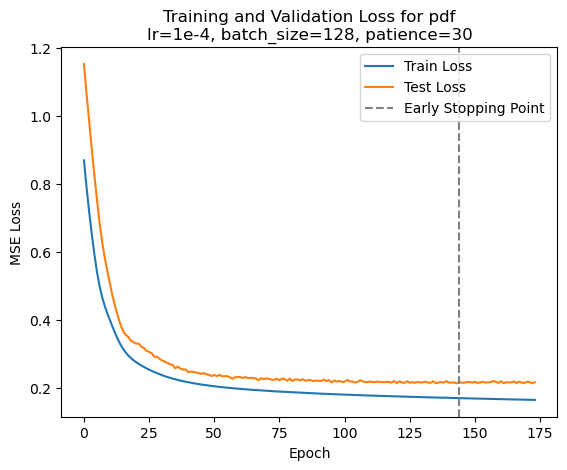

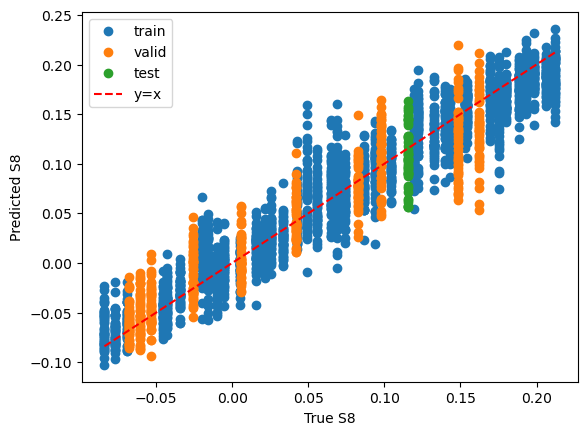

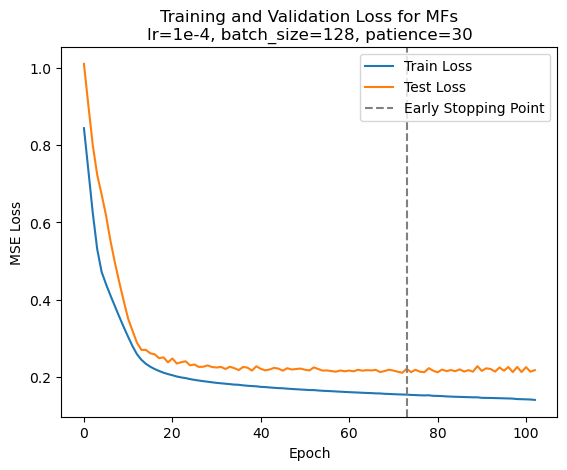

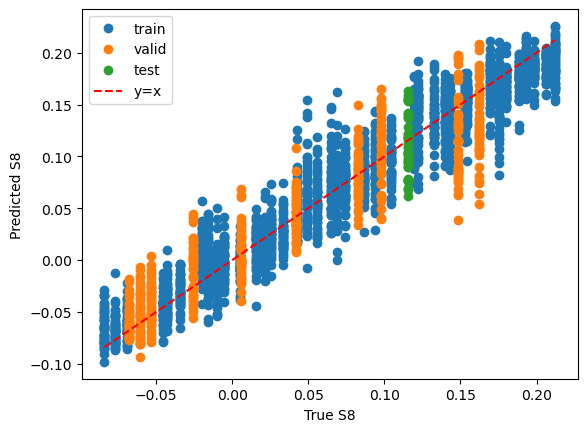

In [24]:
theta_trained = {}

for k in train_data.keys():

    # x_train, x_test, theta_train_normalized, theta_test_normalized, x_mean, x_std, theta_mean, theta_std = train_data[k]
    model, loss_train, loss_test, bad_epochs = train_model(train_data[k]['x_train'], train_data[k]['theta_train'], train_data[k]['x_valid'], train_data[k]['theta_valid'], device)
    theta_mean = train_data[k]['theta_mean']
    theta_std = train_data[k]['theta_std']
    
    plt.plot(loss_train, label="Train Loss")
    plt.plot(loss_test, label="Test Loss")

    end_epoch = len(loss_train) - bad_epochs
    ymin, ymax = plt.gca().get_ylim()
    plt.vlines(end_epoch, ymin=ymin, ymax=ymax, colors='grey', linestyles='dashed', label='Early Stopping Point')
    plt.ylim(ymin, ymax)  # Ensure the y-limits remain the same after adding the vertical line
    plt.legend()

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Training and Validation Loss for {}\nlr=1e-4, batch_size=128, patience=30".format(k))
    plt.show()

    with torch.no_grad():
        pred_train = model(train_data[k]['x_train'])
        pred_valid = model(train_data[k]['x_valid'])
        pred_test = model(train_data[k]['x_test'])

    S8_train = ((train_data[k]['theta_train'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
    S8_pred = ((pred_train[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()

    plt.plot(S8_train, S8_pred, 'o', label='train')

    S8_valid = ((train_data[k]['theta_valid'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
    S8_pred = ((pred_valid[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()

    plt.plot(S8_valid, S8_pred, 'o', label='valid')

    S8_test = ((train_data[k]['theta_test'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
    S8_pred = ((pred_test[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()

    plt.plot(S8_test, S8_pred, 'o', label='test')

    limits = [
        S8_train.min().item(), S8_train.max().item()
    ]

    plt.plot(limits, limits, 'r--', label='y=x')  # Add a reference line for y=x
    plt.xlabel('True S8')
    plt.ylabel('Predicted S8')
    plt.legend()
    plt.show()
 
    theta_trained[k] = (pred_train, pred_valid, pred_test)

# step 2: SBI

In [25]:
from sbi.inference import SNPE
from sbi.utils import BoxUniform

# posterior_nn location differs slightly between sbi versions
try:
    from sbi.neural_nets import posterior_nn
except ImportError:
    from sbi.utils.get_nn_models import posterior_nn

/tmp/ipykernel_232575/1760096567.py:1: FutureWarning: `sbi.inference.SNPE` is deprecated since sbi v0.27.0 and will be removed in v0.28.0. Use `sbi.inference.NPE_C` instead.
  from sbi.inference import SNPE


In [26]:
theta_train_normalized = train_data['C_ell']['theta_train']
theta_valid_normalized = train_data['C_ell']['theta_valid']
theta_test_normalized = train_data['C_ell']['theta_test']
theta_mean = train_data['C_ell']['theta_mean']
theta_std = train_data['C_ell']['theta_std']

theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
theta_train = torch.concat([theta_train, theta_valid], dim=0)

theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)



pred_train_concat = []
pred_valid_concat = []
pred_test_concat = []
for k in theta_trained.keys():
    pred_train, pred_valid, pred_test = theta_trained[k]
    pred_train_concat.append(pred_train)
    pred_valid_concat.append(pred_valid)
    pred_test_concat.append(pred_test)

/tmp/ipykernel_232575/1017190876.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/tmp/ipykernel_232575/1017190876.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/tmp/ipykernel_232575/1017190876.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)


In [27]:
pred_train_concat = torch.concat(pred_train_concat, dim=1)
pred_valid_concat = torch.concat(pred_valid_concat, dim=1)
pred_test_concat = torch.concat(pred_test_concat, dim=1)


pred_train = torch.concat([pred_train_concat, pred_valid_concat], dim=0)        # sbi does valid splitting itself.
pred_test = pred_test_concat

print(pred_train.shape, pred_test.shape)

torch.Size([2450, 10]) torch.Size([50, 10])


In [28]:
theta_all = torch.concatenate([theta_train, theta_valid, theta_test], dim=0)
prior = BoxUniform(
    low=torch.tensor([theta_all[:,0].min()-0.01, theta_all[:,1].min()-0.01], dtype=torch.float32),
    high=torch.tensor([theta_all[:,0].max()+0.01, theta_all[:,1].max()+0.01], dtype=torch.float32),
)

In [29]:
density_estimator = posterior_nn(
    model="mdn",            # maybe try different model here?
    hidden_features=32,
    num_components=5,
)

# density_estimator = posterior_nn(
#     model="maf",
#     hidden_features=32,
#     num_components=5,
# )

In [30]:
inference = SNPE(
    prior=prior,
    density_estimator=density_estimator,
    device=device,
)

inference = inference.append_simulations(
    theta_train,
    pred_train,
)

trained_density_estimator = inference.train(
    training_batch_size=128,
    learning_rate=2e-4,

    # sbi takes a fraction of x_train as its internal validation set
    validation_fraction=0.2,

    stop_after_epochs=20,
    max_num_epochs=500,

    show_train_summary=True,
)

summary = inference.summary

 Neural network successfully converged after 115 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 115
        Best validation performance: -4.0483
        -------------------------
        


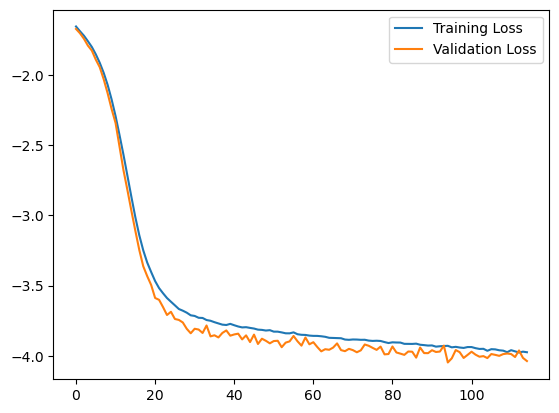

In [31]:
plt.plot(summary['training_loss'], label='Training Loss')
plt.plot(summary['validation_loss'], label='Validation Loss')
plt.legend()

In [32]:
posterior = inference.build_posterior(
    trained_density_estimator
)

In [33]:
import numpy as np
import pandas as pd

# Example: use the same bounds as your BoxUniform prior
prior_low = np.array([
    theta_train[:,0].min() - 0.01,
    theta_train[:,1].min() - 0.01,
])

prior_high = np.array([
    theta_train[:,0].max() + 0.01,
    theta_train[:,1].max() + 0.01,
])

acceptance_threshold = 0.5   # e.g. flag < 10%

low_acceptance = []

for i in range(len(pred_test)):

    samples_raw = posterior.sample(
        (20000,),
        x=pred_test[i],
        reject_outside_prior=False,
        show_progress_bars=False,
    ).cpu().detach().numpy()

    # samples_raw shape: (20000, 2)
    inside = np.all(
        (samples_raw >= prior_low) &
        (samples_raw <= prior_high),
        axis=1,
    )

    acceptance_rate = inside.mean()

    if acceptance_rate < acceptance_threshold:

        # assuming theta_test[:,0] = S8
        #          theta_test[:,1] = Om
        true_S8 = theta_test[i, 0].item()
        true_Om = theta_test[i, 1].item()

        median = np.median(samples_raw, axis=0)

        low_acceptance.append({
            "index": i,
            "S8_true": true_S8,
            "Om_true": true_Om,
            "acceptance_rate": acceptance_rate,
            "S8_raw_median": median[0],
            "Om_raw_median": median[1],
        })

        print(
            f"i={i:4d} | "
            f"accept={acceptance_rate:.4f} | "
            f"S8={true_S8:.4f}, Om={true_Om:.4f}"
        )

low_acceptance_df = pd.DataFrame(low_acceptance)

/tmp/ipykernel_232575/1086265733.py:21: UserWarning: 7.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/tmp/ipykernel_232575/1086265733.py:21: UserWarning: 8.1% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/tmp/ipykernel_232575/1086265733.py:21: UserWarning: 9.6% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/tmp/ipykernel_232575/1086265733.py:21: UserWarning: 50.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/tmp/ipykernel_232575/1086265733.py:21: UserWarning: 20.9% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to inc

i=  27 | accept=0.4975 | S8=0.8019, Om=0.1406


/tmp/ipykernel_232575/1086265733.py:21: UserWarning: 5.9% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(


truth = [0.80186    0.14061001]
raw median = [0.82074773 0.20119137]
raw 16/84 = [[0.79380456 0.16593535]
 [0.84646847 0.23798016]]
raw min = [0.69852346 0.01642597]
raw max = [0.9191536 0.553831 ]


Text(0, 0.5, '$\\Omega_m$')

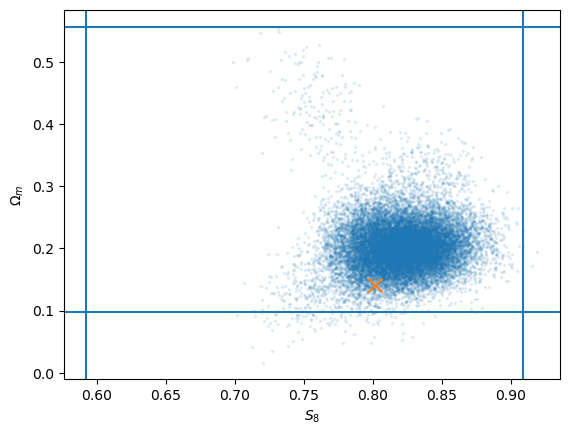

In [34]:
i = 10   # for example, one of your suspicious cases
x_obs = pred_test[i]

samples_raw = posterior.sample(
    (20000,),
    x=x_obs,
    reject_outside_prior=False,
    show_progress_bars=False,
).cpu().detach().numpy()

print("truth =", theta_test[i].numpy())

print("raw median =", np.median(samples_raw, axis=0))
print("raw 16/84 =", np.percentile(samples_raw, [16, 84], axis=0))

print("raw min =", samples_raw.min(axis=0))
print("raw max =", samples_raw.max(axis=0))

plt.scatter(
    samples_raw[:, 0],
    samples_raw[:, 1],
    s=2,
    alpha=0.1,
)

plt.axvline(prior.low[0])
plt.axvline(prior.high[0])

plt.axhline(prior.low[1])
plt.axhline(prior.high[1])

plt.scatter(
    theta_test[i, 0],
    theta_test[i, 1],
    marker="x",
    s=100,
)

plt.xlabel(r"$S_8$")
plt.ylabel(r"$\Omega_m$")

In [35]:
xx = np.linspace(0, 1, 30)
cover = [[] for _ in range(len(xx))]

for i in range(len(pred_test)):
    samples = posterior.sample(
        (5000,),
        x=pred_test[i],
        show_progress_bars=False,
    )[:, 0].cpu().numpy()

    for x, l in zip(xx, cover):
        q_low, q_high = np.quantile(samples, [(1 - x)/2, 1 - (1 - x)/2])
        truth = theta_test[i, 0].item()
        l.append(q_low <= truth <= q_high)

In [36]:
cover = np.mean(cover, axis=1)

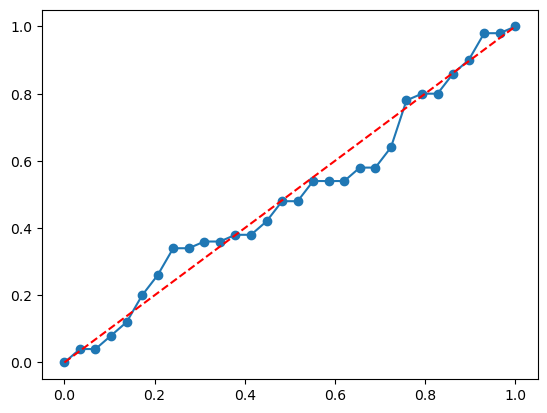

In [37]:
plt.plot(xx, cover, 'o-', label='Observed coverage')
plt.plot([0, 1], [0, 1], 'r--', label='Ideal coverage')

In [38]:
constrained_S8 = []
bias_test = []
pull_test = []
for i in range(len(pred_test)):
    x_obs = pred_test[i]

    samples = posterior.sample(
        (10000,),
        x=x_obs,
        show_progress_bars=False,
    )

    samples_np = samples[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

    true_S8 = theta_test[i, 0]

    constrained_S8.append((q16, q50, q84))

    sigma = 0.5 * (q84 - q16)
    pull = (q50 - true_S8) / sigma
    bias_test.append(q50 - true_S8)
    pull_test.append(pull)

Text(0, 0.5, 'Inferred $S_8$ with 68% CI')

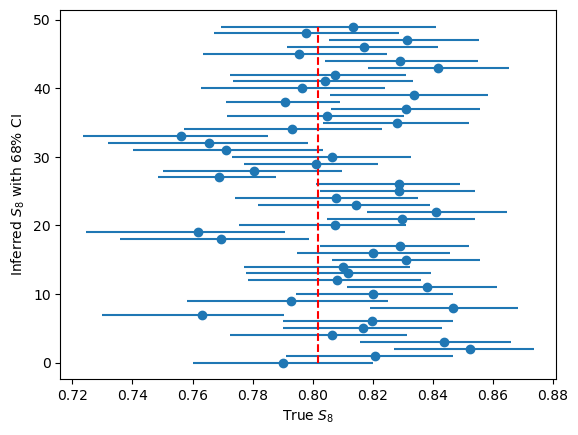

In [39]:
plt.errorbar(
    x = [q50 for q16, q50, q84 in constrained_S8],
    y = np.arange(len(constrained_S8)),
    xerr=[
        [q50 - q16 for q16, q50, q84 in constrained_S8],
        [q84 - q50 for q16, q50, q84 in constrained_S8],
    ],
    fmt='o',
)

plt.plot(
    [theta_test[i, 0].item() for i in range(len(pred_test))],
    np.arange(len(pred_test)),
    'r--',
)

plt.xlabel(r"True $S_8$")
plt.ylabel(r"Inferred $S_8$ with 68% CI")

# leave one out

In [40]:
type(posterior)

sbi.inference.posteriors.direct_posterior.DirectPosterior

In [41]:
import os
os.makedirs(dir, exist_ok=True)

pull_all = []
bias_all = []
for leaveoutindex in range(50):

    train_data = {}

    train_data['C_ell'] = train_test_split_cosmo(C_ell_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)       # random state should be the same.
    train_data['peaks'] = train_test_split_cosmo(peak_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
    train_data['minima'] = train_test_split_cosmo(min_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
    train_data['pdf'] = train_test_split_cosmo(pdf_concat, label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)
    train_data['MFs'] = train_test_split_cosmo(np.concatenate([V0_concat, V1_concat, V2_concat], axis=2), label=np.c_[S8, Om], leaveoutindex=leaveoutindex, random_state=42)

    theta_trained = {}

    for k in train_data.keys():

        # x_train, x_test, theta_train_normalized, theta_test_normalized, x_mean, x_std, theta_mean, theta_std = train_data[k]
        model, loss_train, loss_test, bad_epochs = train_model(train_data[k]['x_train'], train_data[k]['theta_train'], train_data[k]['x_valid'], train_data[k]['theta_valid'], device)
        theta_mean = train_data[k]['theta_mean']
        theta_std = train_data[k]['theta_std']
        

        end_epoch = len(loss_train) - bad_epochs

        with torch.no_grad():
            pred_train = model(train_data[k]['x_train'])
            pred_valid = model(train_data[k]['x_valid'])
            pred_test = model(train_data[k]['x_test'])

        S8_train = ((train_data[k]['theta_train'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
        S8_pred = ((pred_train[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()

        S8_valid = ((train_data[k]['theta_valid'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
        S8_pred = ((pred_valid[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()


        S8_test = ((train_data[k]['theta_test'][:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()
        S8_pred = ((pred_test[:,0] + theta_mean[0]) * theta_std[0]).cpu().numpy()


        theta_trained[k] = (pred_train, pred_valid, pred_test)

    theta_train_normalized = train_data['C_ell']['theta_train']
    theta_valid_normalized = train_data['C_ell']['theta_valid']
    theta_test_normalized = train_data['C_ell']['theta_test']
    theta_mean = train_data['C_ell']['theta_mean']
    theta_std = train_data['C_ell']['theta_std']

    theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
    theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
    theta_train = torch.concat([theta_train, theta_valid], dim=0)

    theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)



    pred_train_concat = []
    pred_valid_concat = []
    pred_test_concat = []
    for k in theta_trained.keys():
        pred_train, pred_valid, pred_test = theta_trained[k]
        pred_train_concat.append(pred_train)
        pred_valid_concat.append(pred_valid)
        pred_test_concat.append(pred_test)
    pred_train_concat = torch.concat(pred_train_concat, dim=1)
    pred_valid_concat = torch.concat(pred_valid_concat, dim=1)
    pred_test_concat = torch.concat(pred_test_concat, dim=1)


    pred_train = torch.concat([pred_train_concat, pred_valid_concat], dim=0)        # sbi does valid splitting itself.
    pred_test = pred_test_concat

    print(pred_train.shape, pred_test.shape)
    theta_all = torch.concatenate([theta_train, theta_valid, theta_test], dim=0)
    prior = BoxUniform(
        low=torch.tensor([theta_all[:,0].min()-0.01, theta_all[:,1].min()-0.01], dtype=torch.float32),
        high=torch.tensor([theta_all[:,0].max()+0.01, theta_all[:,1].max()+0.01], dtype=torch.float32),
    )


    density_estimator = posterior_nn(
        model="mdn",            # maybe try different model here?
        hidden_features=32,
        num_components=5,
    )

    inference = SNPE(
        prior=prior,
        density_estimator=density_estimator,
        device=device,
    )

    inference = inference.append_simulations(
        theta_train,
        pred_train,
    )

    trained_density_estimator = inference.train(
        training_batch_size=128,
        learning_rate=2e-4,

        # sbi takes a fraction of x_train as its internal validation set
        validation_fraction=0.2,

        stop_after_epochs=20,
        max_num_epochs=500,

        show_train_summary=True,
    )

    summary = inference.summary
    posterior = inference.build_posterior(
        trained_density_estimator
    )
    constrained_S8 = []
    bias_test = []
    pull_test = []

    xx = np.linspace(0, 1, 30)
    coverage = [[] for _ in range(len(xx))]

    for i in range(len(pred_test)):
        x_obs = pred_test[i]

        try:
            samples = posterior.sample(
                (10000,),
                x=x_obs,
                show_progress_bars=False,
                max_sampling_time=60,   # 1 minute
            )

            samples_np = samples[:, 0].cpu().numpy()

            truth = theta_test[i, 0].item()

            for x, l in zip(xx, coverage):
                q_low, q_high = np.quantile(
                    samples_np,
                    [(1 - x) / 2, 1 - (1 - x) / 2]
                )
                l.append(q_low <= truth <= q_high)

            q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

            constrained_S8.append((q16, q50, q84))

            sigma = 0.5 * (q84 - q16)
            bias_test.append(q50 - truth)
            pull_test.append((q50 - truth) / sigma)

        except RuntimeError as e:
            constrained_S8.append((np.nan, np.nan, np.nan))
            bias_test.append(np.nan)
            pull_test.append(np.nan)

            for l in coverage:
                l.append(np.nan)

            print(f"sampler failed for leaveoutindex={leaveoutindex}, i={i}: {e}")

    np.savez(f'{dir}/{leaveoutindex}_results.npz', 
        bias_test=bias_test, pull_test=pull_test, 
        true_S8 = theta_test[:,0].cpu().numpy(),
        constrained_S8=constrained_S8,
        coverage=coverage,
    )
    # pull_all.append(pull_test)
    # bias_all.append(bias_test)


/tmp/ipykernel_232575/473927798.py:52: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_train = (theta_train_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/tmp/ipykernel_232575/473927798.py:53: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_valid = (theta_valid_normalized * theta_std + theta_mean).to(dtype=torch.float32)
/tmp/ipykernel_232575/473927798.py:56: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  theta_test = (theta_test_normalized * theta_std + theta_mean).to(dtype=torch.float32)


torch.Size([2450, 10]) torch.Size([50, 10])
 Neural network successfully converged after 181 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 181
        Best validation performance: -4.0253
        -------------------------
        
torch.Size([2450, 10]) torch.Size([50, 10])
 Neural network successfully converged after 163 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 163
        Best validation performance: -4.0368
        -------------------------
        
torch.Size([2450, 10]) torch.Size([50, 10])
 Neural network successfully converged after 112 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 112
        Best validation performance: -3.9700
        -------------------------
        
torch.Size([2450, 10]) torch.Size([50, 1